## Cities and Settlements Air Quality Clustering
This project clusters cities and settlements with sufficient long-term WHO air quality measurements based on PM2.5, PM10 and NO2 concentrations. Population is retained as a contextual variable for post-clustering analysis.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import itertools

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture

from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
from sklearn.metrics import adjusted_rand_score

### Dataset
The dataset is taken from the WHO Ambient Air Quality Database and contains air pollution measurements and population-related information for urban settlements worldwide.

In [3]:
file_path = "data/who_ambient_air_quality_database_version_2024_(v6.1).xlsx"

excel_file = pd.ExcelFile(file_path)
excel_file.sheet_names

['Readme', 'Metadata', 'Update 2024 (V6.1)']

In [4]:
df = pd.read_excel(
    file_path, 
    sheet_name="Update 2024 (V6.1)"
    )

df.head()

,who_region,iso3,country_name,city,year,version,pm10_concentration,pm25_concentration,no2_concentration,pm10_tempcov,pm25_tempcov,no2_tempcov,type_of_stations,reference,web_link,population,population_source,latitude,longitude,who_ms
0,4_Eur,ESP,Spain,A Coruna/ESP,2013.0,"V4.0 (2018), V4.0 (2018), V4.0 (2018), V4.0 (2...",23.238,11.491,28.841,87.0,46.0,93.0,"Urban, Urban, Suburban",NaN,NaN,246146.0,"manual, manual, manual, manual",43.367900,-8.418571,1
1,4_Eur,ESP,Spain,A Coruna/ESP,2014.0,"V6.0 (2023), V6.0 (2023), V6.0 (2023)",27.476,15.878,19.575,96.0,88.0,95.0,"Urban, Urban, Suburban",NaN,NaN,247604.0,NaN,43.368033,-8.418233,1
2,4_Eur,ESP,Spain,A Coruna/ESP,2015.0,"V6.0 (2023), V6.0 (2023), V6.0 (2023), V6.0...",25.515,14.004,22.731,98.0,71.0,98.0,"Urban, Urban, Suburban, Suburban",NaN,NaN,247604.0,NaN,43.370375,-8.422900,1
3,4_Eur,ESP,Spain,A Coruna/ESP,2016.0,"V6.0 (2023), V6.0 (2023), V6.0 (2023), V6.0...",23.057,13.160,20.204,98.0,98.0,98.0,"Urban, Urban, Suburban, Suburban",NaN,NaN,247604.0,NaN,43.370375,-8.422900,1
4,4_Eur,ESP,Spain,A Coruna/ESP,2017.0,"V6.0 (2023), V6.0 (2023), V6.0 (2023), V6.0...",26.849,14.114,21.543,97.0,97.0,98.0,"Urban, Urban, Suburban, Suburban",NaN,NaN,247604.0,NaN,43.370375,-8.422900,1


### Initial Data Inspection
Before preprocessing, the structure, size, data types and missing values of the dataset are examined.

In [5]:
df.shape

(40098, 20)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 40098 entries, 0 to 40097
Data columns (total 20 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   who_region          40098 non-null  str    
 1   iso3                40098 non-null  str    
 2   country_name        40098 non-null  str    
 3   city                40098 non-null  str    
 4   year                40095 non-null  float64
 5   version             40098 non-null  str    
 6   pm10_concentration  28672 non-null  float64
 7   pm25_concentration  21730 non-null  float64
 8   no2_concentration   26934 non-null  float64
 9   pm10_tempcov        22403 non-null  float64
 10  pm25_tempcov        16590 non-null  float64
 11  no2_tempcov         23402 non-null  float64
 12  type_of_stations    23331 non-null  str    
 13  reference           6652 non-null   str    
 14  web_link            1790 non-null   str    
 15  population          22433 non-null  float64
 16  population_sour

### Missing Value Analysis
Missing values are examined before deciding how to handle incomplete observations.

In [7]:
missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percentage": (df.isna().sum() / len(df) * 100).round(2)
})

missing_summary.sort_values(
    by = "missing_percentage",
    ascending = False
)

,missing_count,missing_percentage
web_link,38308,95.54
reference,33446,83.41
pm25_tempcov,23508,58.63
population_source,21996,54.86
pm25_concentration,18368,45.81
pm10_tempcov,17695,44.13
population,17665,44.05
type_of_stations,16767,41.82
no2_tempcov,16696,41.64
no2_concentration,13164,32.83


### Observation Granularity
The dataset may contain multiple observations for the same urban settlement across different years. The observation structure is examined before preprocessing and clustering.

In [8]:
granularity_summary = pd.Series({
    "total_rows": len(df),
    
    "unique_cities": df[
        ["country_name", "city"]
    ].drop_duplicates().shape[0],

    "unique_city_year_pairs": df[
        ["country_name", "city", "year"]
    ].drop_duplicates().shape[0],

    "duplicate_city_year_pairs": df.duplicated(
        subset=["country_name", "city", "year"],
    ).sum()
})

granularity_summary

total_rows                   40098
unique_cities                 7182
unique_city_year_pairs       40098
duplicate_city_year_pairs        0
dtype: int64

### Temporal Coverage
The number of available years for each urban settlement is examined to determine whether there is sufficient temporal coverage for city-level aggregation.

In [9]:
df["year"].agg(["min", "max"])

min    2010.0
max    2022.0
Name: year, dtype: float64

In [10]:
year_counts = (
    df["year"].value_counts().sort_index()
)

year_counts

year
2010.0    2878
2011.0     802
2012.0     971
2013.0    3869
2014.0    3460
2015.0    4096
2016.0    4131
2017.0    3820
2018.0    4678
2019.0    4594
2020.0    3983
2021.0    2654
2022.0     159
Name: count, dtype: int64

In [11]:
yearly_coverage = (
    df.groupby("year")
    .agg(
        observations=("city", "size"),
        pm25_available=("pm25_concentration", "count"),
        pm10_available=("pm10_concentration", "count"),
        no2_available=("no2_concentration", "count")
    )
)

yearly_coverage

,observations,pm25_available,pm10_available,no2_available
year,,,,
2010.0,2878,930,2200,2171
2011.0,802,354,587,302
2012.0,971,416,741,327
2013.0,3869,1592,3000,2731
2014.0,3460,1626,2704,2301
2015.0,4096,2238,3017,2624
2016.0,4131,2404,2966,2881
2017.0,3820,2166,2661,2666
2018.0,4678,2986,2799,2868


In [12]:
pollution_columns = [
    "pm25_concentration",
    "pm10_concentration",
    "no2_concentration"
]

candidate_periods = [
    (2013, 2021),
    (2014, 2021),
    (2015, 2021),
]

period_comparison = []

for start_year,  end_year in candidate_periods:
    temp = df[
        (df["year"] >= start_year) & (df["year"] <= end_year)
].copy()

    city_summary = (
        temp.groupby(["country_name", "city"])
        .agg(
            pm25=("pm25_concentration", "median"),
            pm10=("pm10_concentration", "median"),
            no2=("no2_concentration", "median"),
            years_available=("year", "nunique")
        )
        .reset_index()
    )

    city_summary["available_pollutants"] = (
        city_summary[["pm25", "pm10", "no2"]].notna().sum(axis=1)
    )

    period_comparison.append({
        "period": f"{start_year}-{end_year}",
        "unique_cities": len(city_summary),

        "cities_with_1_pollutant": (
            city_summary["available_pollutants"] >= 1
        ).sum(),

        "cities_with_2_pollutants": (
            city_summary["available_pollutants"] >= 2
        ).sum(),

        "cities_with_3_pollutants": (
            city_summary["available_pollutants"] == 3
        ).sum(),

        "median_years_available": city_summary["years_available"].median()
})

period_comparison = pd.DataFrame(period_comparison)

period_comparison

,period,unique_cities,cities_with_1_pollutant,cities_with_2_pollutants,cities_with_3_pollutants,median_years_available
0,2013-2021,6577,6577,4270,2380,6.0
1,2014-2021,5986,5986,3907,2216,6.0
2,2015-2021,5877,5877,3850,2191,6.0


In [13]:
analysis_df = df[
    (df["year"] >= 2013) & (df["year"] <= 2021)
].copy()

In [14]:
city_coverage = (
    analysis_df
    .groupby(["country_name", "city"])
    .agg(
        years_available=("year", "nunique"),
        pm25_years=("pm25_concentration", "count"),
        pm10_years=("pm10_concentration", "count"),
        no2_years=("no2_concentration", "count")
    )
    .reset_index()
)

city_coverage[
    [
        "years_available",
        "pm25_years",
        "pm10_years",
        "no2_years"
    ]
].describe()

,years_available,pm25_years,pm10_years,no2_years
count,6577.000000,6577.000000,6577.000000,6577.000000
mean,5.364908,3.036947,3.802189,3.662004
std,3.138534,3.310246,3.668346,3.732739
min,1.000000,0.000000,0.000000,0.000000
25%,2.000000,0.000000,0.000000,0.000000
50%,6.000000,2.000000,2.000000,2.000000
75%,9.000000,6.000000,8.000000,8.000000
max,9.000000,9.000000,9.000000,9.000000


### Minimum Measurement Requirement
Different minimum measurement-year requirements are compared to evaluate the trade-off measurement coverage and the number of cities retained for clustering.

In [15]:
coverage_thresholds = []

for min_years in range(1, 10):
    eligible_cities = city_coverage[
        (city_coverage["pm25_years"] >= min_years) &
        (city_coverage["pm10_years"] >= min_years) &
        (city_coverage["no2_years"] >= min_years)
    ]

    coverage_thresholds.append({
        "minimum_pollutant_years": min_years,
        "coverage_percentage": round(min_years / 9 * 100, 1),
        "eligible_cities": len(eligible_cities)
    })

coverage_thresholds = pd.DataFrame(coverage_thresholds)

coverage_thresholds

,minimum_pollutant_years,coverage_percentage,eligible_cities
0,1,11.1,2380
1,2,22.2,1707
2,3,33.3,1456
3,4,44.4,1283
4,5,55.6,1148
5,6,66.7,1042
6,7,77.8,946
7,8,88.9,781
8,9,100.0,522


### Final City Selection
Cities are retained only if PM2.5, PM10 and NO2 measurements are each available for at least 7 of 9 years between 2013 and 2021. This ensures a consistent minimum temporal coverage of 77.8% across all clustering features.

In [16]:
eligible_cities = city_coverage[
    (city_coverage["pm25_years"] >= 7) &
    (city_coverage["pm10_years"] >= 7) &
    (city_coverage["no2_years"] >= 7)
].copy()

eligible_cities.shape

(946, 6)

### City-Level Aggregation
The selected city-year observations are aggregated into a single long-term pollution profile for each city using median PM2.5, PM10 and NO2 concentrations. Median population is retained separately as a contextual variable for post-clustering profiling and is not used as an input to the clustering models.

In [17]:
selected_records = analysis_df.merge(
    eligible_cities[["country_name", "city"]],
    on=["country_name", "city"],
    how="inner"
)

selected_records.shape

(8241, 20)

In [18]:
city_data = (
    selected_records
    .groupby(["country_name", "city"])
    .agg(
        pm25=("pm25_concentration", "median"),
        pm10=("pm10_concentration", "median"),
        no2=("no2_concentration", "median"),
        population=("population", "median")
    )
    .reset_index()
)

city_data.head()

,country_name,city,pm25,pm10,no2,population
0,Albania,Durres/ALB,14.323,24.559,23.898,NaN
1,Australia,Adelaide/AUS,7.100,16.657,0.005,1336403.0
2,Australia,Darwin/AUS,8.100,19.800,5.100,92530.0
3,Austria,Braunau Am Inn/AUT,12.504,17.018,18.144,16197.0
4,Austria,Dornbirn/AUT,9.693,15.317,29.293,45922.0


In [19]:
city_data.shape

(946, 6)

In [20]:
city_data.isna().sum()

country_name      0
city              0
pm25              0
pm10              0
no2               0
population      203
dtype: int64

### EDA
The distributions and relationships of city-level features are examined before preprocessing and clustering.

In [21]:
city_data[
    ["pm25", "pm10", "no2"]
].describe()

,pm25,pm10,no2
count,946.000000,946.000000,946.000000
mean,12.465284,20.565465,19.431006
std,5.179345,6.910083,10.005569
min,1.855000,2.939000,0.005000
25%,8.962750,16.160000,11.900000
50%,11.643500,19.578000,19.357750
75%,14.571500,24.210250,26.091500
max,32.905500,59.452500,54.528000


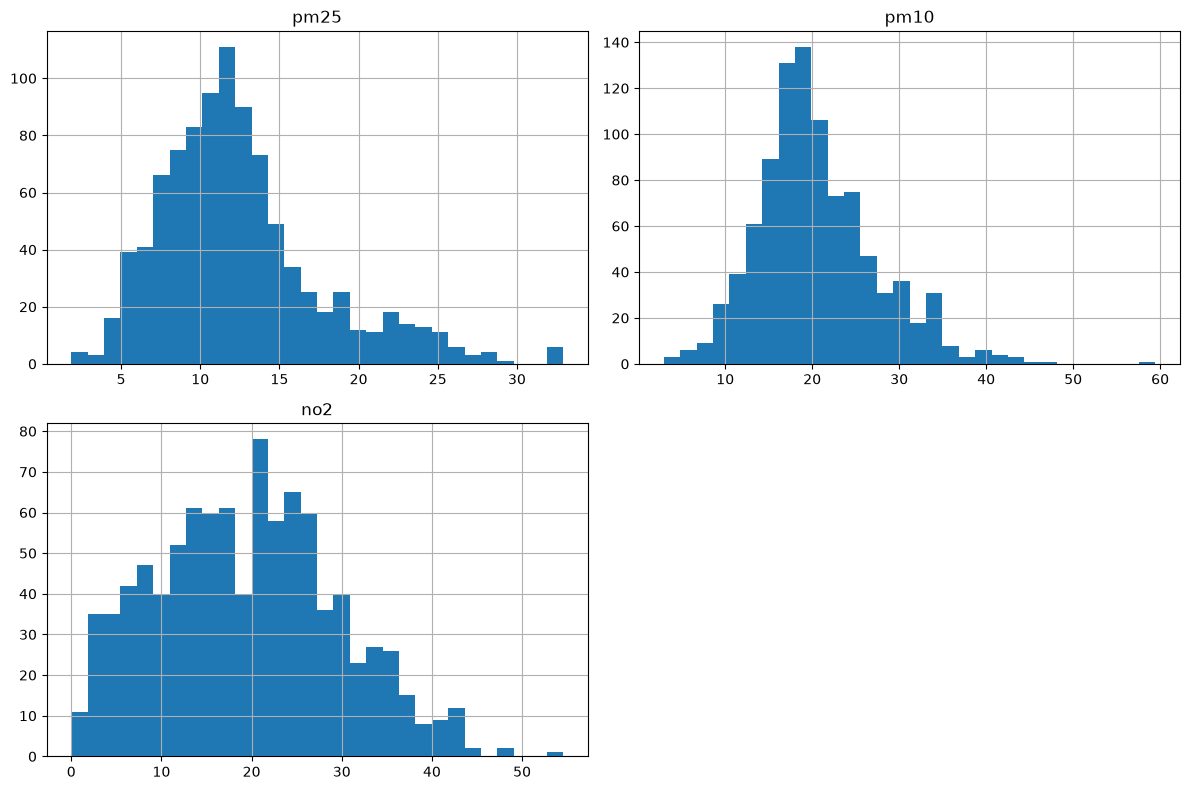

In [22]:
features = ["pm25", "pm10", "no2"]

city_data[features].hist(bins=30, figsize=(12, 8))

plt.tight_layout()
plt.show()

### Skewness and Outliers
Feature skewness and potential outliers are examined before deciding whether transformations are needed.

In [23]:
city_data[["pm25", "pm10", "no2"]].skew()

pm25    1.087107
pm10    0.806589
no2     0.259129
dtype: float64

### Outlier Inspection
Boxplots are used to examine potential extreme values in the clustering features before applying transformations or scaling.

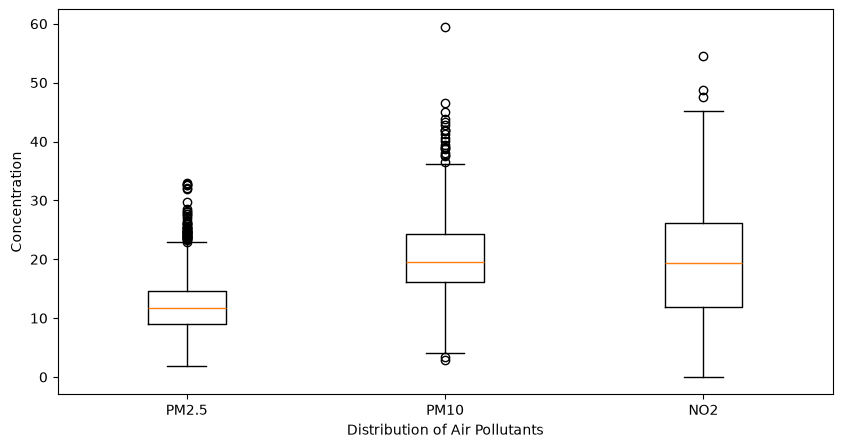

In [24]:
plt.figure(figsize=(10, 5))

plt.boxplot(
    [
        city_data["pm25"],
        city_data["pm10"],
        city_data["no2"],
    ],
    tick_labels=["PM2.5", "PM10", "NO2"]
)

plt.ylabel("Concentration")
plt.xlabel("Distribution of Air Pollutants")
plt.show()

In [25]:
print("Highest PM2.5:")
display(
    city_data.nlargest(10, "pm25")[
        ["country_name", "city", "pm25"]
    ]
)

print("Highest PM10:")
display(
    city_data.nlargest(10, "pm10")[
        ["country_name", "city", "pm10"]
    ]
)

print("Lowest NO2:")
display(
    city_data.nsmallest(10, "no2")[
        ["country_name", "city", "no2"]
    ]
)

Highest PM2.5:


,country_name,city,pm25
593,Poland,Krakow/POL,32.9055
599,Poland,Nowy Sacz/POL,32.8390
583,Poland,Gliwice/POL,32.6395
662,South Africa,Sedibeng/ZAF,32.6320
81,Czechia,Dolni Lutyne/CZE,32.0680
588,Poland,Katowice/POL,31.9330
605,Poland,Piotrkow Trybunalski/POL,29.7265
577,Poland,Bielsko Biala/POL,28.5125
98,Czechia,Ostrava/CZE,28.1340
496,Italy,Soresina/ITA,28.0270


Highest PM10:


,country_name,city,pm10
662,South Africa,Sedibeng/ZAF,59.4525
888,United States of America,Hanford Corcoran CA/USA,46.5000
583,Poland,Gliwice/POL,44.9330
593,Poland,Krakow/POL,43.7905
588,Poland,Katowice/POL,43.2745
66,Bulgaria,Plovdiv/BGR,42.7320
660,South Africa,Gert Sibande/ZAF,41.8960
661,South Africa,Johannesburg/ZAF,41.8890
663,South Africa,Waterberg/ZAF,41.7220
599,Poland,Nowy Sacz/POL,41.2855


Lowest NO2:


,country_name,city,no2
1,Australia,Adelaide/AUS,0.0050
805,Sweden,Stromsund/SWE,0.4200
566,Norway,Groa/NOR,0.4800
564,Norway,Birkeland/NOR,0.9820
919,United States of America,Riverton WY/USA,1.0500
628,Portugal,Cedros/PRT,1.0955
757,Spain,Retuerta De Bullaque/ESP,1.2060
772,Spain,Santiz/ESP,1.2170
217,France,Venaco/FRA,1.4130
349,Iceland,Grundarhverfi/ISL,1.6220


In [26]:
selected_records[
    (selected_records["country_name"] == "Australia") &
    (selected_records["city"] == "Adelaide/AUS" )
][
    ["year", "no2_concentration"]
].sort_values("year")

,year,no2_concentration
50,2013.0,0.005
51,2014.0,0.005
52,2015.0,0.005
53,2016.0,0.004
54,2017.0,13.455
55,2018.0,12.109
56,2019.0,11.571


In [27]:
selected_records[
    (selected_records["country_name"] == "Australia")
][
    ["city", "year", "no2_concentration"]
].sort_values(["city", "year"])

,city,year,no2_concentration
50,Adelaide/AUS,2013.0,0.005
51,Adelaide/AUS,2014.0,0.005
52,Adelaide/AUS,2015.0,0.005
53,Adelaide/AUS,2016.0,0.004
54,Adelaide/AUS,2017.0,13.455
55,Adelaide/AUS,2018.0,12.109
56,Adelaide/AUS,2019.0,11.571
1810,Darwin/AUS,2013.0,7.800
1811,Darwin/AUS,2014.0,8.000
1812,Darwin/AUS,2015.0,5.100


In [28]:
selected_records[
    (selected_records["country_name"] == "Australia") &
    (selected_records["city"] == "Adelaide/AUS" )
][
    [
        "year", 
        "pm25_concentration",
        "pm10_concentration",
        "no2_concentration",
        "reference",
        "web_link"
    ]
].sort_values("year")

,year,pm25_concentration,pm10_concentration,no2_concentration,reference,web_link
50,2013.0,7.250,16.871,0.005,"EPA South Australia, EPA South Australia, EPA ...","http://www.epa.sa.gov.au/, http://www.epa.sa.g..."
51,2014.0,7.100,16.657,0.005,"EPA South Australia, EPA South Australia, EPA ...","http://www.epa.sa.gov.au/, http://www.epa.sa.g..."
52,2015.0,7.450,16.057,0.005,"EPA South Australia, EPA South Australia, EPA ...","http://www.epa.sa.gov.au/, http://www.epa.sa.g..."
53,2016.0,6.875,16.186,0.004,"EPA South Australia, EPA South Australia, EPA ...","http://www.epa.sa.gov.au/, http://www.epa.sa.g..."
54,2017.0,7.540,16.471,13.455,"EPA South Australia, EPA South Australia, EPA ...","http://www.epa.sa.gov.au/, http://www.epa.sa.g..."
55,2018.0,6.780,19.214,12.109,"EPA South Australia, EPA South Australia, EPA ...","http://www.epa.sa.gov.au/, http://www.epa.sa.g..."
56,2019.0,6.140,20.643,11.571,"EPA South Australia, EPA South Australia, EPA ...","http://www.epa.sa.gov.au/, http://www.epa.sa.g..."


### Measurement Consistency Check
Extreme within-city changes across years are examined to identify potential unit or reporting inconsistencies before clustering.

In [29]:
def max_min_ratio(series):
    values = series.dropna()
    values = values[values > 0]

    if len(values) < 2:
        return np.nan
    
    return values.max() / values.min()

consistency_check = (
    selected_records
    .groupby(["country_name", "city"])
    .agg(
        pm25_ratio=("pm25_concentration", max_min_ratio),
        pm10_ratio=("pm10_concentration", max_min_ratio),
        no2_ratio=("no2_concentration", max_min_ratio)
    )
    .reset_index()
)

consistency_check.sort_values(
    "no2_ratio",
    ascending=False
).head(15)

,country_name,city,pm25_ratio,pm10_ratio,no2_ratio
1,Australia,Adelaide/AUS,1.228013,1.285608,3363.750000
808,Sweden,Uppsala/SWE,1.544016,2.909049,18.269140
64,Bulgaria,Chepelare/BGR,1.441501,1.466453,7.889216
136,France,Beaumarches/FRA,1.843920,1.725373,6.487136
729,Spain,Laza/ESP,1.328516,2.351080,5.935098
792,Spain,Villalba De Guardo/ESP,1.567034,1.537466,5.441931
568,Norway,Hurdal/NOR,1.704433,1.483088,5.326582
450,Italy,Montemonaco/ITA,1.301990,1.954022,4.842574
467,Italy,Portoscuso/ITA,2.667268,1.496427,4.741372
630,Portugal,Conceicao/PRT,2.015617,2.278640,4.595031


In [30]:
selected_records[
    (
        (selected_records["country_name"] == "Australia") &
        (selected_records["city"] == "Adelaide/AUS")
    ) 
    |
    (
        (selected_records["country_name"] == "Sweden") &
        (selected_records["city"] == "Uppsala/SWE")
    )
][
    ["country_name", "city", "year", "no2_concentration"]
].sort_values(["country_name", "city", "year"])

,country_name,city,year,no2_concentration
50,Australia,Adelaide/AUS,2013.0,0.005
51,Australia,Adelaide/AUS,2014.0,0.005
52,Australia,Adelaide/AUS,2015.0,0.005
53,Australia,Adelaide/AUS,2016.0,0.004
54,Australia,Adelaide/AUS,2017.0,13.455
55,Australia,Adelaide/AUS,2018.0,12.109
56,Australia,Adelaide/AUS,2019.0,11.571
7408,Sweden,Uppsala/SWE,2013.0,17.980
7409,Sweden,Uppsala/SWE,2014.0,18.127
7410,Sweden,Uppsala/SWE,2015.0,17.305


### Data Consistency Adjustment
A consistency check identified a substantial discontinuity in Adelaide's NO2 measurements. Values from 2013-2016 were several orders of magnitude lower than those from 2017-2019, while the other pollutant measurements remained on comparable scales. Since the discrepancy could not be reliably corrected, Adelaide was excluded from the clustering dataset rather than imputing or rescaling uncertain values.

In [31]:
city_data = city_data[
    ~(
        (city_data["country_name"] == "Australia") &
        (city_data["city"] == "Adelaide/AUS")
    )
].copy()

city_data.shape

(945, 6)

### Feature Correlation
Correlations between the clustering features are examined to identify strongly related variables that may provide overlapping information.

In [32]:
correlation_matrix = city_data[
    ["pm25", "pm10", "no2"]
].corr()

correlation_matrix

,pm25,pm10,no2
pm25,1.000000,0.809191,0.444239
pm10,0.809191,1.000000,0.427125
no2,0.444239,0.427125,1.000000


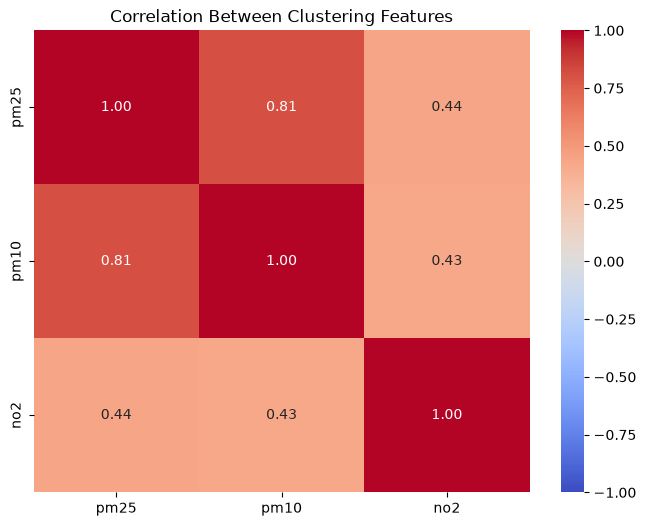

In [33]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1, vmax=1
)

plt.title("Correlation Between Clustering Features")
plt.show()

### Feature Preprocessing
Right-skewed features are log-transformed before scaling to reduce the influence of extreme values while preserving the relative ordering of cities. NO2 is retained in its original form because its distribution is approximately symmetric.

In [34]:
model_data = city_data[
    ["pm25", "pm10", "no2"]
].copy()

model_data["pm25"] = np.log1p(model_data["pm25"])
model_data["pm10"] = np.log1p(model_data["pm10"])

model_data.head()

,pm25,pm10,no2
0,2.729355,3.240990,23.898
2,2.208274,3.034953,5.100
3,2.602986,2.891371,18.144
4,2.369589,2.792208,29.293
5,2.667784,3.036202,17.675


In [35]:
model_data.skew()

pm25   -0.131574
pm10   -0.525339
no2     0.262169
dtype: float64

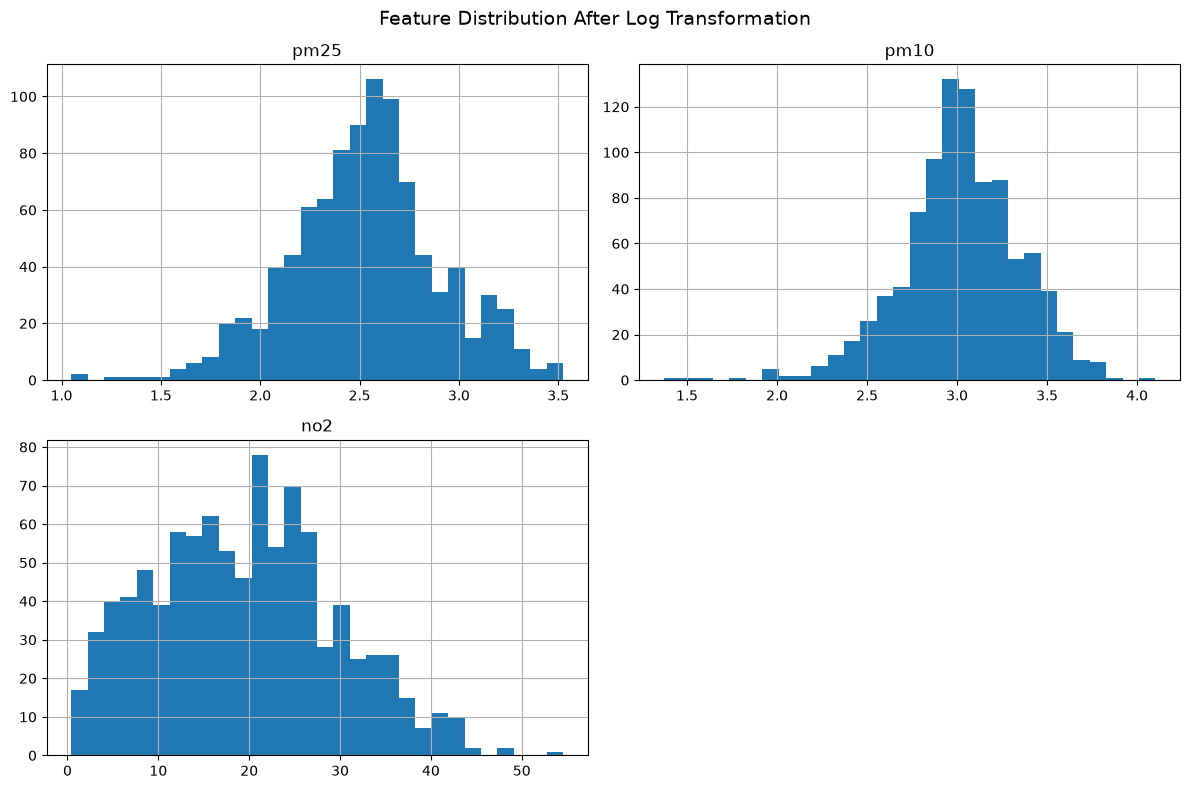

In [36]:
model_data.hist(bins=30, figsize=(12, 8))

plt.suptitle(
    "Feature Distribution After Log Transformation", 
    fontsize=14
)

plt.tight_layout()
plt.show()

### Feature Scaling
The transformed features are standardized so that differences in measurements scale do not cause individual variables to dominate the clustering algorithms.

In [37]:
scaler = StandardScaler()

scaled_data = scaler.fit_transform(model_data)

scaled_data = pd.DataFrame(
    scaled_data,
    columns=model_data.columns,
    index=model_data.index
)

scaled_data.head()

,pm25,pm10,no2
0,0.528119,0.671769,0.445286
2,-0.855987,0.047354,-1.437230
3,0.192455,-0.387785,-0.130945
4,-0.427498,-0.688310,0.985566
5,0.364572,0.051140,-0.177913


In [38]:
scaled_data.mean()

pm25   -4.812141e-16
pm10    9.774662e-16
no2    -7.518971e-17
dtype: float64

In [39]:
scaled_data.std(ddof=0)

pm25    1.0
pm10    1.0
no2     1.0
dtype: float64

### PCA
PCA is used to examine the main dimensions of variation in the standardized features and to obtain a two-dimensional representation for cluster visualization.

In [40]:
pca = PCA()

pca.fit(scaled_data)

explained_variance = pd.DataFrame({
    "component": ["PC1", "PC2", "PC3"],
    "explained_variance_ratio": pca.explained_variance_ratio_
})

explained_variance

,component,explained_variance_ratio
0,PC1,0.734201
1,PC2,0.201761
2,PC3,0.064038


In [41]:
pca_loadings = pd.DataFrame(
    pca.components_,
    columns=scaled_data.columns,
    index=["PC1", "PC2", "PC3"]
)

pca_loadings

,pm25,pm10,no2
PC1,0.617361,0.609289,0.497627
PC2,-0.317380,-0.385895,0.866230
PC3,0.719816,-0.692714,-0.044860


In [42]:
pca_coordinates = pca.transform(scaled_data)

pca_data = pd.DataFrame(
    pca_coordinates[:, :2],
    columns=["PC1", "PC2"],
    index=scaled_data.index
)

pca_data.head()

,PC1,PC2
0,0.956928,-0.041126
2,-1.214805,-0.991573
3,-0.182620,-0.024866
4,-0.192857,1.255022
5,0.167698,-0.289556


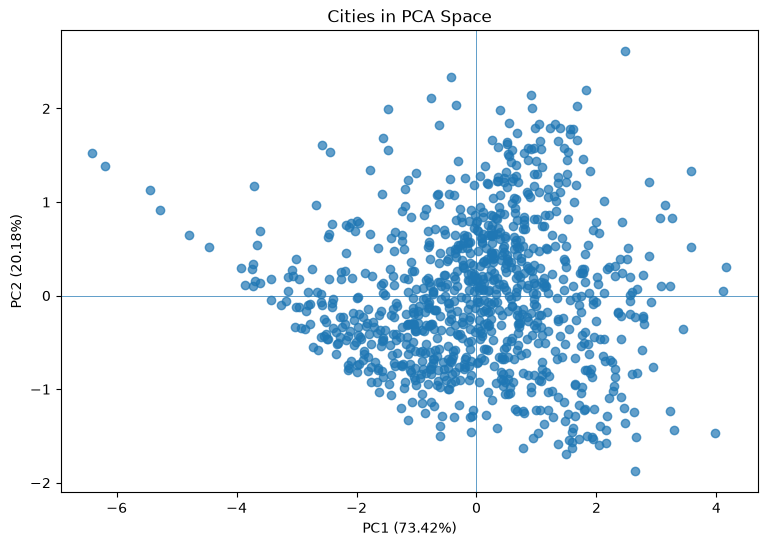

In [43]:
plt.figure(figsize=(9, 6))

plt.scatter(
    pca_data["PC1"], 
    pca_data["PC2"], 
    alpha=0.7
)

pc1_percentage = pca.explained_variance_ratio_[0] * 100
pc2_percentage = pca.explained_variance_ratio_[1] * 100

plt.xlabel(f"PC1 ({pc1_percentage:.2f}%)")
plt.ylabel(f"PC2 ({pc2_percentage:.2f}%)")
plt.title("Cities in PCA Space")

plt.axhline(0, linewidth=0.5)
plt.axvline(0, linewidth=0.5)

plt.show()

### K-Means Cluster Evaluation
Different numbers of clusters are evaluated using multiple internal clustering metrics before selecting the final number of clusters.

In [44]:
kmeans_results = []

for k in range(2, 9):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20,
    )

    labels = kmeans.fit_predict(scaled_data)

    kmeans_results.append({
        "k": k,
        "silhouette_score": silhouette_score(scaled_data, labels),
        "calinski_harabasz_score": calinski_harabasz_score(scaled_data, labels),
        "davies_bouldin_score": davies_bouldin_score(scaled_data, labels),
        "inertia": kmeans.inertia_
    })

kmeans_results = pd.DataFrame(kmeans_results)

kmeans_results

,k,silhouette_score,calinski_harabasz_score,davies_bouldin_score,inertia
0,2,0.385315,789.236399,0.962039,1543.325727
1,3,0.336473,682.001614,1.016867,1158.094650
2,4,0.319198,687.028648,1.004807,888.627124
3,5,0.290223,637.497801,1.052346,763.583587
4,6,0.285540,600.298233,1.018686,675.566799
5,7,0.282760,573.697164,1.024868,607.104774
6,8,0.288226,562.118595,1.008467,545.256076


### Elbow Method
The elbow method is used to examine how inertia decreases as the number of clusters increases.

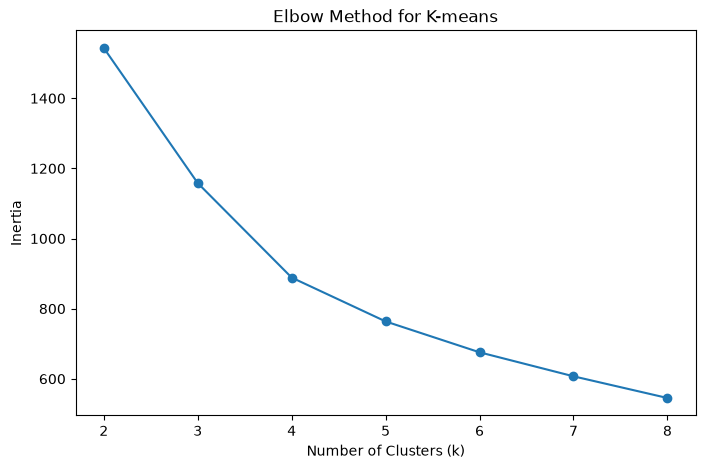

In [45]:
plt.figure(figsize=(8, 5))

plt.plot(
    kmeans_results["k"],
    kmeans_results["inertia"],
    marker="o",
)

plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method for K-means")

plt.show()

In [46]:
candidate_profiles = []

for k in range(2, 5):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    labels = model.fit_predict(scaled_data)

    temp = city_data[
        ["pm25", "pm10", "no2"]
    ].copy() 

    temp["cluster"] = labels

    profile = (
        temp
        .groupby("cluster")
        .agg(
            cities=("pm25", "size"),
            pm25=("pm25", "median"),
            pm10=("pm10", "median"),
            no2=("no2", "median")
        )
        .reset_index()
    )

    profile.insert(0, "k", k)

    candidate_profiles.append(profile)

candidate_profiles = pd.concat(
    candidate_profiles,
    ignore_index=True
)

candidate_profiles

,k,cluster,cities,pm25,pm10,no2
0,2,0,381,8.4790,15.3020,10.23700
1,2,1,564,13.6980,22.1880,24.55025
2,3,0,294,7.9330,14.6085,8.39800
3,3,1,468,12.0620,19.8895,23.22850
4,3,2,183,19.6540,29.8410,24.02100
5,4,0,186,19.6310,29.6785,23.59000
6,4,1,321,10.5270,18.7080,14.19600
7,4,2,283,12.3165,19.7600,26.94700
8,4,3,155,6.8465,12.1450,5.97400


### Final Number of Clusters
The two-cluster solution was selected as the final K-means configuration. Among the evaluated solutions, k=2 achieved the highest Silhouette and Calinski-Harabasz score and the lowest Davies-Bouldin score. The candidate cluster profiles also showed two interpretable air pollution groups.

In [47]:
final_kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=20
)

final_labels = final_kmeans.fit_predict(scaled_data)

city_data["cluster"] = final_labels

In [48]:
final_profile = (
    city_data
    .groupby("cluster")
    .agg(
        cities=("city", "size"),
        pm25=("pm25", "median"),
        pm10=("pm10", "median"),
        no2=("no2", "median"),
        population_median=("population", "median"),
        population_available=("population", "count")
    )
)

final_profile

,cities,pm25,pm10,no2,population_median,population_available
cluster,,,,,,
0,381,8.479,15.302,10.23700,98183.5,250
1,564,13.698,22.188,24.55025,133422.5,492


In [49]:
(
    city_data
    .merge(
        df[["country_name", "city", "who_region"]].drop_duplicates(["country_name", "city"]),
        on=["country_name", "city"],
        how="left"
    )["who_region"]
    .value_counts()
)

who_region
4_Eur    850
2_Amr     87
6_Wpr      4
1_Afr      4
Name: count, dtype: int64

### Final Cluster Profiles
The final two-cluster solution reveals two relative air pollution profiles.

- **Cluster 0 - Lower Pollution Profile:** Contains 381 cities and shows lower median concentrations of PM2.5, PM10 and NO2 across all three pollutants.
- **Cluster 1 - Higher Pollution Profile:** Contains 564 cities and shows higher median concentrations across all three pollutants, with particularly higher NO2 levels.

Population was not used as an input to the clustering model. It is included only for post-clustering profiling and population data are not available for all cities. Therefore, differences in population should be interpreted as contextual characteristics rather than factors that determined cluster membership.

In [50]:
cluster_names = {
    0: "Lower Pollution Cluster",
    1: "Higher Pollution Cluster"
}

city_data["cluster_name"] = city_data["cluster"].map(cluster_names)

city_data.head()

,country_name,city,pm25,pm10,no2,population,cluster,cluster_name
0,Albania,Durres/ALB,14.323,24.559,23.898,NaN,1,Higher Pollution Cluster
2,Australia,Darwin/AUS,8.100,19.800,5.100,92530.0,0,Lower Pollution Cluster
3,Austria,Braunau Am Inn/AUT,12.504,17.018,18.144,16197.0,1,Higher Pollution Cluster
4,Austria,Dornbirn/AUT,9.693,15.317,29.293,45922.0,1,Higher Pollution Cluster
5,Austria,Eisenstadt/AUT,13.408,19.826,17.675,13101.0,1,Higher Pollution Cluster


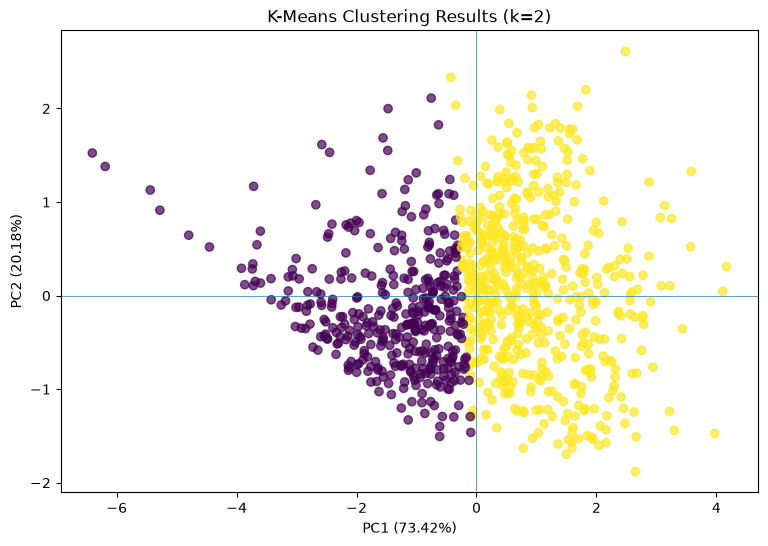

In [51]:
plt.figure(figsize=(9, 6))

plt.scatter(
    pca_data["PC1"], 
    pca_data["PC2"],
    c=city_data["cluster"],
    cmap="viridis",
    alpha=0.7
)

plt.xlabel(f"PC1 ({pc1_percentage:.2f}%)")
plt.ylabel(f"PC2 ({pc2_percentage:.2f}%)")
plt.title("K-Means Clustering Results (k=2)")

plt.axhline(0, linewidth=0.5)
plt.axvline(0, linewidth=0.5)

plt.show()

### Comparison with Alternative Clustering Methods
The final two-cluster solution is compared across K-means, Agglomerative Clustering and Gaussian Mixture Models. The same standardized features and number of clusters are used for each method to compare their internal clustering performance.

In [52]:
models = {
    "K-Means": KMeans(
        n_clusters=2,
        random_state=42,
        n_init=20
    ),

    "Agglomerative": AgglomerativeClustering(
        n_clusters=2,
    ),

    "Gaussian Mixture": GaussianMixture(
        n_components=2,
        random_state=42
    )
}

In [53]:
model_results = []

for name, model in models.items():

    labels = model.fit_predict(scaled_data)

    model_results.append({
        "model": name,
        "silhouette_score": silhouette_score(scaled_data, labels),
        "calinski_harabasz_score": calinski_harabasz_score(scaled_data, labels),
        "davies_bouldin_score": davies_bouldin_score(scaled_data, labels)
    })

model_results = pd.DataFrame(model_results)

model_results

,model,silhouette_score,calinski_harabasz_score,davies_bouldin_score
0,K-Means,0.385315,789.236399,0.962039
1,Agglomerative,0.332649,610.885448,1.080128
2,Gaussian Mixture,0.273758,400.483721,1.314394


### Visual Comparison of Clustering Methods
The cluster assignments produced by each method are visualized in the same two-dimensional PCA space. PCA is used only for visualization; all clustering models are fitted using the full standardized feature set.

In [54]:
model_labels = {}

for name, model in models.items():
    model_labels[name] = model.fit_predict(scaled_data)

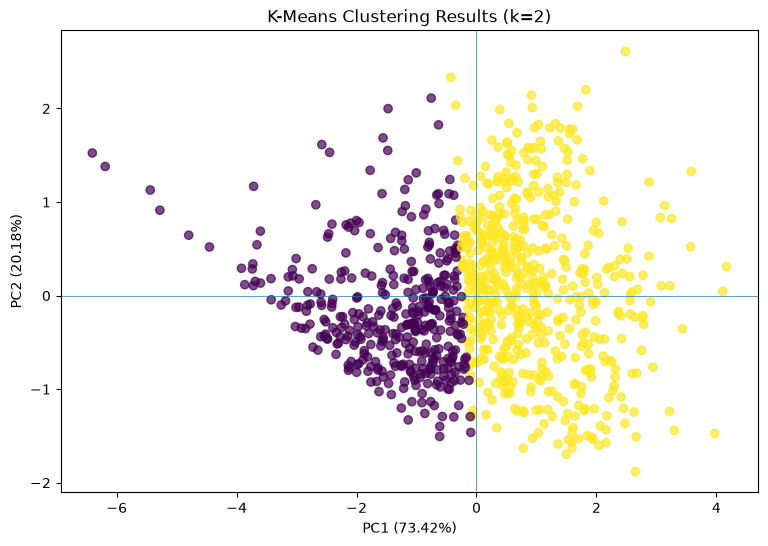

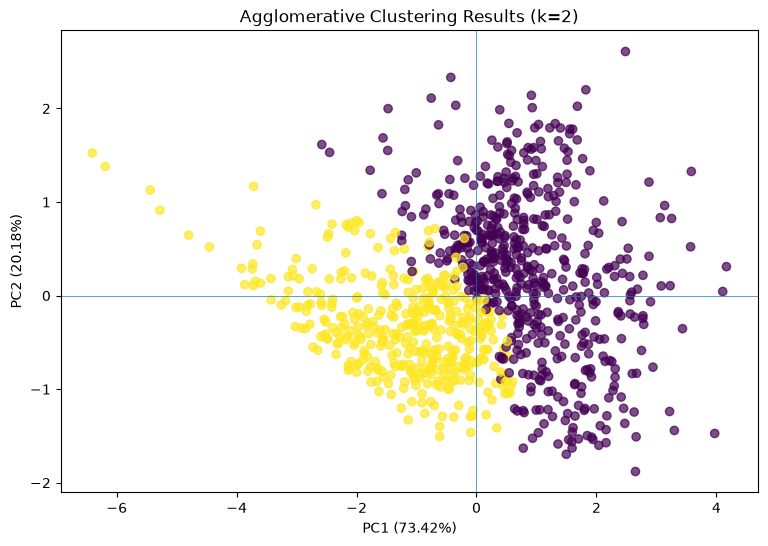

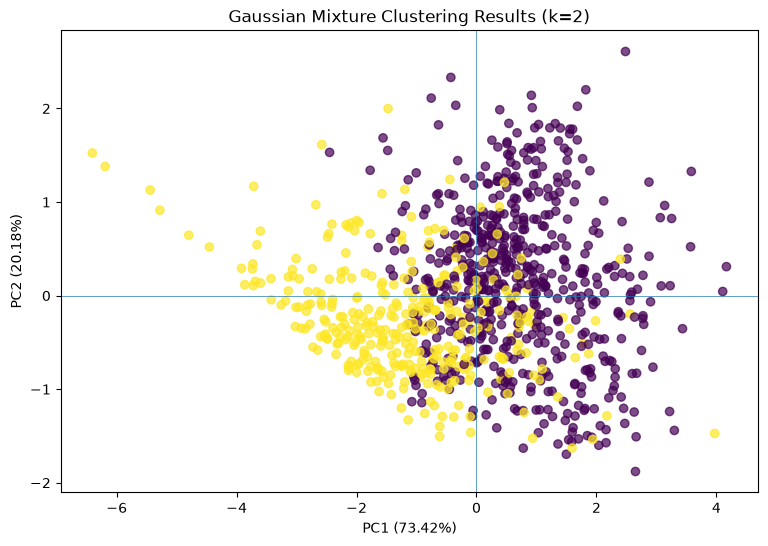

In [55]:
for name, labels in model_labels.items():

    plt.figure(figsize=(9, 6))

    plt.scatter(
        pca_data["PC1"], 
        pca_data["PC2"],
        c=labels,
        cmap="viridis",
        alpha=0.7
    )

    plt.xlabel(f"PC1 ({pc1_percentage:.2f}%)")
    plt.ylabel(f"PC2 ({pc2_percentage:.2f}%)")
    plt.title(f"{name} Clustering Results (k=2)")

    plt.axhline(0, linewidth=0.5)
    plt.axvline(0, linewidth=0.5)

    plt.show()

In [56]:
alternative_profiles = []

for name, labels in model_labels.items():

    temp = city_data[
        ["pm25", "pm10", "no2"]
    ].copy() 

    temp["cluster"] = labels

    profile = (
        temp
        .groupby("cluster")
        .agg(
            cities=("pm25", "size"),
            pm25=("pm25", "median"),
            pm10=("pm10", "median"),
            no2=("no2", "median")
        )
        .reset_index()
    )

    profile.insert(0, "model", name)

    alternative_profiles.append(profile)

alternative_profiles = pd.concat(
    alternative_profiles,
    ignore_index=True
)

alternative_profiles

,model,cluster,cities,pm25,pm10,no2
0,K-Means,0,381,8.4790,15.30200,10.23700
1,K-Means,1,564,13.6980,22.18800,24.55025
2,Agglomerative,0,539,13.5030,22.02900,25.24150
3,Agglomerative,1,406,9.0590,16.61600,10.70750
4,Gaussian Mixture,0,598,13.2865,20.50075,23.95500
5,Gaussian Mixture,1,347,8.3810,17.09600,10.42400


In [57]:
ari_results = []

for (name_a,labels_a), (name_b, labels_b) in itertools.combinations(model_labels.items(), 2):
    ari_results.append({
        "method_a": name_a,
        "method_b": name_b,
        "ARI": adjusted_rand_score(labels_a, labels_b)
    })

pd.DataFrame(ari_results)

,method_a,method_b,ARI
0,K-Means,Agglomerative,0.584623
1,K-Means,Gaussian Mixture,0.402321
2,Agglomerative,Gaussian Mixture,0.353411


### Model Comparison Results
Among the evaluated clustering methods, K-means achieved the highest Silhouette and Calinski-Harabasz and the lowest Davies-Bouldin score for the two-cluster solution. Therefore, K-means was retained as the final clustering method.

The number of clusters was selected separately through the K-means cluster evaluation, where k=2 provided the strongest overall internal validation results. 

### Comparison of Cluster Profiles Across Methods
Although cluster labels are arbitrary and differ between algorithms, all three methods identify broadly similar pollution profiles. Each method produces one cluster characterized by relatively lower median PM2.5, PM10 and NO2 concentrations and another characterized by higher concentrations across the three pollutants. 

The median pollutant levels of these profiles are similar across K-Means, Agglomerative Clustering and Gaussian Mixture Models. However, the agreement between the cluster assignments is moderate (ARI: K-Means vs Agglomerative 0.58, K-Means vs GMM 0.40, Agglomerative vs GMM 0.35). The general lower-versus-higher pollution pattern is shared across methods, but the placement of cities near the boundary depends on the algorithm.

### Conclusion
The analysis identified two relative air pollution profiles among the 945 cities included in the final dataset. One group was characterized by consistently lower median PM2.5, PM10 and NO2 concentrations while the other showed higher concentrations across all three pollutants.

Although different clustering algorithms assigned some cities differently, they revealed broadly similar lower-versus-higher pollution patterns. Overall, the results suggest that air pollution in the selected cities forms a continuum that can be roughly summarized as a lower and a higher pollution group (silhouette score 0.39), although the boundary between the groups is not sharp.

### Limitations
- The analysis includes only cities with sufficient long-term PM2.5, PM10 and NO2 coverage between 2013 and 2021. Therefore, the final sample should not be interpreted as globally representative of all cities or regions. Most of the cities in the sample (850 of 945, about 90%) are located in Europe, so the results mainly reflect European monitoring networks.

- Annual measurements were aggregated into city-level median values. This provides a stable long-term pollution profile but does not capture year-to-year trends, sudden changes or temporal patterns within individual cities.

- Population was not used as a clustering feature and was available only for a subset of cities. It was retained solely as contextual information for interpreting the final clusters.